# GATE (Listmode Reconstruction; With Time of Flight)

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("PET/GATE-mMR-BrainInWater")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("PET/GATE-mMR-BrainInWater")

PET/GATE-mMR-BrainInWater: already downloaded


In [2]:
from __future__ import annotations
import torch
import numpy as np
import pytomography
from pytomography.metadata import ObjectMeta
from pytomography.metadata.PET import PETLMProjMeta, PETTOFMeta
from pytomography.projectors.PET import PETLMSystemMatrix
from pytomography.algorithms import OSEM
from pytomography import io
from pytomography.likelihoods import PoissonLogLikelihood
from pytomography.transforms.shared import GaussianFilter
import matplotlib.pyplot as plt
from pytomography.utils import sss
import gc

Reading the ROOT files takes a few minutes for each kind of coincidence, so the reader below keeps each result in `OUTPUT`, and later runs of this tutorial load it from there:

In [3]:
# The first run reads the ROOT files and caches each result in OUTPUT; later runs load the cache.
# Set this to True to recompute everything.
LOAD_FROM_ROOT = False

`io.PET.read_gate` reads the simulation: the scanner from its GATE macro, and the coincidences from its 54 ROOT files. It returns the events (pairs of crystal numbers, and a TOF bin when asked for), the object grid placed in the patient, and the projection metadata, whose `info` describes the scanner for every PET function in PyTomography. GATE's world has no patient in it; the dataset registry records how the phantom sat in it, and `read_gate` uses that for this dataset, so the images line up with the phantom's MR.

In [4]:
path = DATA / 'PET' / 'GATE-mMR-BrainInWater'
macro = path / 'mMR_Geometry.mac'  # the scanner, as the simulation's GATE macro describes it
paths = [path / 'simple_phantom' / f'mMR_voxBrain_withSimplePhantom_{i}.root' for i in range(1, 55)]  # its 54 runs


def read_gate(events, tof_meta=None, normalization=None):
    """io.PET.read_gate for one kind of coincidence: (events, object_meta, proj_meta). Reading the 54 ROOT files takes
    a few minutes, so the first run keeps the result in OUTPUT and later runs load it from there."""
    name = f'gate_{events}' + ('' if tof_meta is None else f'_tof{tof_meta.num_bins}') + ('' if normalization is None else '_norm')
    cache = OUTPUT / f'{name}.pt'
    if LOAD_FROM_ROOT or not cache.exists():
        # doi: the lines of response end 9 mm inside the crystals, the mean depth of interaction
        torch.save(io.PET.read_gate(paths, macro, events=events, tof_meta=tof_meta, normalization=normalization,
                                    doi=9), cache)
    return torch.load(cache, weights_only=False)

We can look at the information of our PET scanner:

Set up time of flight metadata:

* Since GATE tracks the times, the time of flight bins can be set up however one wishes. The only thing that is dependent on the GATE simulation is `fwhm_tof_resolution`, which in our case is 550ps
* With 21 TOF bins, a sinogram of this scanner takes 34.6 GB. The scatter estimate below never holds one; see the next section.

In [5]:
speed_of_light = 0.3 #mm/ps
fwhm_tof_resolution = 550 * speed_of_light / 2 #ps to position along LOR
TOF_range = 1000 * speed_of_light #ps to position along LOR (full range)
num_tof_bins = 21
tof_meta = PETTOFMeta(num_tof_bins, TOF_range, fwhm_tof_resolution, n_sigmas=3)

## How much memory this needs

Set `RAM_GB` to the memory this tutorial may use, and pass it to `pytomography.set_memory_budget`. Every memory-heavy step then splits its work to fit: the sensitivity image goes through the scanner's 411 million crystal pairs in blocks, and the scatter estimate, a 34.6 GB TOF sinogram if held whole, is computed one group of angles at a time while the events read it. Each reconstruction and the scatter estimate print their estimates before they run (`estimate_memory`). The tutorial peaks at about 21 GB (measured on Windows), and needs about that whatever `RAM_GB` is (the same with `RAM_GB = 12`), so it does not fit in 16 GB: the events, their randoms, scatter and sensitivity, and the normalization weights of every crystal pair are held whole, which the budget does not split yet. The results do not depend on the budget.

In [6]:
RAM_GB = 25 # memory (RAM) this tutorial may use, in GB; it needs about 21 GB however low this is
pytomography.set_memory_budget(RAM_GB)

## Normalization Correction

In PET imaging, each detector crystal used in the scanner will have a different response to a uniform source due to its positioning (e.g. crystals at the end of edge of modules are different than those in the center). Adequate PET reconstruction takes this into account by first performing a calibration scan for a scanner and obtaining a normalization correction factor for each crystal pair LOR

The normalization weights corresponding to each pair of detector IDs (due to geometry/crystal orientation) come with the dataset, in `normalization_weights.npy`. `read_gate` takes them as `normalization=` and keeps them in `proj_meta.weights_sensitivity`; the 89 million pairs whose lines of response miss the calibration shell have no weight in the file (NaN), and `read_gate` sets them to 0, with a warning. They were computed from a calibration scan done using a thin cylindrical shell, with `io.PET.gate_normalization`, which computes $\eta$ from the scan's ROOT files. For this it needs

* `cylinder_radius`: The radius of the thin cylindrical shell used for calibration (318 mm)

Randoms were left out of the scan (PyTomography PR #290). The scan itself (36 ROOT files, 46 GB) is in `PET/GATE-mMR-Brain/normalization_scan`, for anyone who wants to compute the weights again.

In [7]:
# The true coincidences in their TOF bins (used from "Primary-Only Reconstruction" on), with the normalization weights
# of every crystal pair. proj_meta.info describes the scanner
detector_ids, object_meta, proj_meta = read_gate('trues', tof_meta=tof_meta,
                                                 normalization=path / 'normalization_weights.npy')
info = proj_meta.info
# The weights come with the dataset. They were computed from the calibration scan (36 ROOT files, 46 GB, in
# PET/GATE-mMR-Brain/normalization_scan), randoms left out (PyTomography PR #290):
# normalization_weights = io.PET.gate_normalization(normalization_paths, info, cylinder_radius=318)
normalization_weights = proj_meta.weights_sensitivity  # read_gate's: one per crystal pair, in torch.combinations order

## Primary-Only Reconstruction

Before we delve into scatter/random modeling, lets get a baseline reconstruction that uses only primary events from the simulated GATE data (i.e. we will manually exclude all scatters/randoms). PyTomography selected such events when it read the ROOT data above (`events='trues'`), and put each in its TOF bin (`tof_meta`; events outside the bins are left out). Obviously this is not doable for clinical data (where we don't know which events are randoms/scatters).

We reconstruct PET listmode data as follows:

* Note: in this case, our sensitivity weights only have contribution from the normalization factor $\eta$ (and not attenuation $\mu$), so we need to include the attenuation map in the system matrix to get the true sensitivity weights

In [8]:
# The reconstruction grid: 128 x 128 x 96 voxels of 2 mm, centred where read_gate placed the scanner in the patient
object_meta = object_meta.with_grid(dr=(2, 2, 2), shape=(128, 128, 96))  # mm, voxels
# The phantom's attenuation map (1/cm), an image in GATE's world: gate_image places it in the patient as read_gate
# placed the scanner, and attenuation_map puts it on the grid, in 1/mm
atten_map = io.attenuation_map(io.PET.gate_image(path / 'umap_mMR_brainSimplePhantom.hv', proj_meta, units='1/cm'),
                               object_meta)
psf_transform = GaussianFilter(3.) # 3mm gaussian blurring
# Create system matrix: read_gate's proj_meta holds the events, the scanner's info, the TOF bins and the normalization
# weights
system_matrix = PETLMSystemMatrix(
    object_meta,
    proj_meta,
    obj2obj_transforms = [psf_transform],
    attenuation_map = atten_map,
    N_splits=8,
)
# Create likelihood. For listmode reconstruction, projections don't need to be provided, since all detection events are stored in proj_meta
likelihood = PoissonLogLikelihood(
    system_matrix,
)
# Initialize reconstruction algorithm
recon_algorithm = OSEM(likelihood)
print(recon_algorithm.estimate_memory(n_subsets=14)) # its peak RAM and GPU memory, before it runs
# Reconstruct
recon_primaryonly = recon_algorithm(n_iters=4, n_subsets=14)

OSEM (PETLMSystemMatrix): 14 subsets, memory budget 25 GB
Peak ~ 10.4 GB RAM, 3.5 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 1.6 GB RAM, 1.1 GB GPU (events and their projector order 1.0 GPU, sensitivity weights 1.6 RAM, sensitivity and normalisation images (14) 0.1 GPU, image, update and attenuation map 0.03 GPU, projections (the data) 0.00 GPU)
  one subset at a time: 0.00 GB RAM, 0.9 GB GPU (expected counts, ratio and temporaries (one subset) 0.1 GPU, positions of the subset's events 0.04 GPU, building a subset's projector order (its first projection) 0.8 GPU)
  projector chunks: 0.00 GB RAM, 0.04 GB GPU (projector chunk 0.04 GPU)
  Python, CUDA, allocator: 5.3 GB RAM, 1.4 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 0.8 GPU, memory the allocators keep (Windows) 2.2 RAM)
To use less: 28 subsets ~ 9.7 GB RAM, 3.0 GB GPU, N_splits 16 ~ 10.4 GB RAM

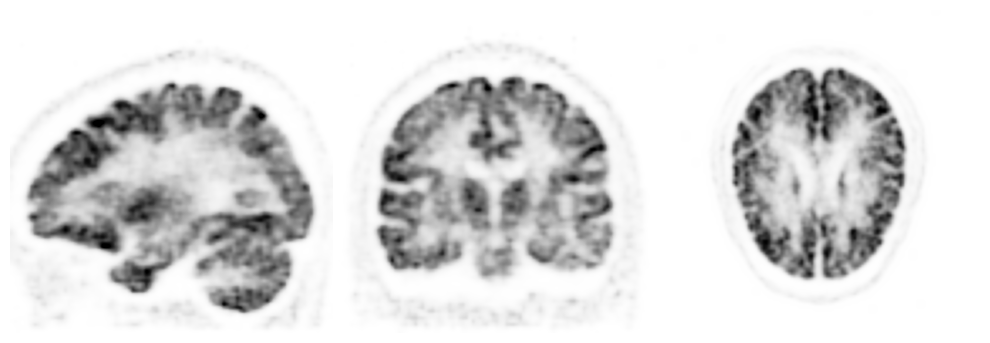

In [9]:
vmax = 0.45
cmap='Greys'
fig, ax = plt.subplots(1,3,figsize=(10,4), gridspec_kw={'wspace': 0.0})
plt.subplot(131)
plt.imshow(recon_primaryonly[50,16:-16].cpu().T, cmap=cmap, interpolation='gaussian', vmax=vmax, origin='lower')
plt.axis('off')
plt.subplot(132)
plt.imshow(recon_primaryonly[16:-16,64].cpu().T, cmap=cmap, interpolation='gaussian', vmax=vmax, origin='lower')
plt.axis('off')
plt.subplot(133)
plt.imshow(recon_primaryonly[:,:,48].cpu().T, cmap=cmap, interpolation='gaussian', vmax=vmax, origin='lower')
plt.axis('off')
fig.tight_layout()
plt.show()

## Reconstruction With Random/Scatter Estimation

For reconstruction of all events, we need to estimate boths randoms and scatters. Lets now get **all** events that were obtained in GATE:

In [10]:
# The primary-only reconstruction is done: free its events and system matrix (and PyTorch's GPU cache) before loading all the events
del detector_ids, proj_meta, system_matrix, likelihood, recon_algorithm
gc.collect()
torch.cuda.empty_cache()
detector_ids, _, _ = read_gate('prompts', tof_meta=tof_meta)

### Randoms

In addition to the first two steps of the non-TOF procedure (obtaining a random sinogram and smoothing), we now also need to account for the fact that the number of randoms in each TOF bin is proportional to the length of the TOF bin divided by the total coincidence timing width. We can do this using the `randoms_sinogram_to_sinogramTOF` function, and then converting back to listmode.

 First lets get all the delayed coincidence events:

In [11]:
detector_ids_delays, _, _ = read_gate('delayeds')

The procedure is

1. Convert listmode delays to sinogram
2. Smooth sinogram
3. Convert sinogram to TOF sinogram
4. Convert TOF sinogram to TOF listmode events

In [12]:
sinogram_randoms_estimate = io.PET.listmode_to_sinogram(
    detector_ids_delays,
    info
)
del detector_ids_delays # binned: the events are not needed again
sinogram_randoms_estimate = io.PET.smooth_randoms_sinogram(
    sinogram_randoms_estimate,
    info,
    fwhm_r=20,
    fwhm_theta=7,
    fwhm_z=40
)
sinogram_randoms_estimate = io.PET.randoms_sinogram_to_sinogramTOF(
    sinogram_randoms_estimate,
    tof_meta = tof_meta,
    coincidence_timing_width = 4300
) # coinicidence timing window for this GATE simulation was set to 4300ps
lm_randoms_estimate = io.PET.sinogram_to_listmode(
    detector_ids,
    sinogram_randoms_estimate,
    info,
)

### Scatters

Like before (non-TOF listmode tutorial), lets get an initial reconstruction without scatter

In [13]:
# The same attenuation map as above, and all the events in their TOF bins with the normalization weights
proj_meta = PETLMProjMeta(
    detector_ids,
    info,
    weights_sensitivity=normalization_weights,
    tof_meta=tof_meta
    )
psf_transform = GaussianFilter(3.)
system_matrix = PETLMSystemMatrix(
       object_meta,
       proj_meta,
       obj2obj_transforms = [psf_transform],
       N_splits=10,
       attenuation_map=atten_map,
)
lm_norm = system_matrix._compute_sensitivity_projection(all_ids=False)
additive_term = lm_randoms_estimate / lm_norm
additive_term[additive_term.isnan()] = 0 # remove NaN values
# Provide the random-only
likelihood = PoissonLogLikelihood(
        system_matrix,
        additive_term = additive_term
    )
recon_algorithm = OSEM(likelihood)
recon_without_scatter_estimation = recon_algorithm(4,14)

Now we perform the scatter estimate and convert back to listmode (like in the previous non-TOF tutorial). There are two additional parameters we need to provide to the function for TOF:

1. `tof_meta`: Provides all the required TOF metadata
2. `num_dense_tof_bins`: The emission integrals in Watson [CITE] are split into multiple regions: this specifies the number of regions. This is independent and seperate from any of the information in `tof_meta`.

With the memory budget set above, the estimate is computed one group of angles at a time while the events read it, instead of as a 34.6 GB sinogram. The events that the estimate is scaled to are binned the same way.

**Note: this takes ~10 minutes to run**

In [14]:
# its peak RAM and GPU memory, before it runs
print(sss.estimate_sss_memory(object_meta, proj_meta, system_matrix, sinogram_random=sinogram_randoms_estimate,
                              tof_meta=tof_meta, sinogram_interring_stepsize=6, sinogram_intraring_stepsize=6,
                              num_dense_tof_bins=25))
scatter_sinogram = sss.get_sss_scatter_estimate(
        object_meta,
        proj_meta,
        recon_without_scatter_estimation,
        atten_map,
        system_matrix,
        sinogram_random=sinogram_randoms_estimate,
        tof_meta=tof_meta,
        num_dense_tof_bins=25,
        image_stepsize=6,
        sinogram_interring_stepsize=6,
        sinogram_intraring_stepsize=6,
        N_splits=1)
lm_scatter_estimate = io.PET.sinogram_to_listmode(proj_meta.detector_ids, scatter_sinogram, proj_meta.info)
# Save memory, these are not needed anymore
del(scatter_sinogram)
del(sinogram_randoms_estimate)
gc.collect()

Single scatter simulation (TOF, lazy, N_splits 1)
Peak ~ 24.1 GB RAM, 5.0 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 5.4 GB RAM, 0.01 GB GPU (PET image and attenuation map 0.01 GPU, randoms 1.6 RAM, events binned lazily 0.9 RAM, sensitivity sinogram of the sinogram system matrix 1.6 RAM, interpolated estimate (lazy: angle and radius of the sampled ring pairs, host) 1.2 RAM)
  projector chunks: 3.4 GB RAM, 3.2 GB GPU (largest step on the host: scaling (93 subsets) 3.4 RAM, sparse estimate (GPU) 0.4 GPU, interpolation over angle and radius (GPU) 0.6 GPU, scaling (93 subsets) (GPU) 2.3 GPU)
  Python, CUDA, allocator: 10.2 GB RAM, 1.8 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 1.2 GPU, memory the allocators keep (Windows) 7.2 RAM)
(plus whatever else your script keeps)


20

Finally, we can perform the reconstruction including both scatters and randoms for estimation.

In [15]:
additive_term = (lm_scatter_estimate + lm_randoms_estimate) / lm_norm
additive_term[additive_term.isnan()] = 0
likelihood = PoissonLogLikelihood(
        system_matrix,
        additive_term = additive_term
    )
recon_algorithm = OSEM(likelihood)
print(recon_algorithm.estimate_memory(n_subsets=14))
recon_lm_tof = recon_algorithm(4,14)

OSEM (PETLMSystemMatrix): 14 subsets, memory budget 25 GB
Peak ~ 13.1 GB RAM, 5.3 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 1.6 GB RAM, 2.3 GB GPU (events and their projector order 1.7 GPU, sensitivity weights 1.6 RAM, sensitivity and normalisation images (14) 0.1 GPU, image, update and attenuation map 0.03 GPU, projections (the data) 0.00 GPU, additive term 0.4 GPU)
  one subset at a time: 0.00 GB RAM, 1.1 GB GPU (expected counts, ratio and temporaries (one subset) 0.1 GPU, positions of the subset's events 0.1 GPU, building a subset's projector order (its first projection) 0.9 GPU)
  projector chunks: 0.00 GB RAM, 0.05 GB GPU (projector chunk 0.05 GPU)
  Python, CUDA, allocator: 6.1 GB RAM, 1.9 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 1.3 GPU, memory the allocators keep (Windows) 3.0 RAM)
To use less: 28 subsets ~ 12.5 GB RAM, 5.0 GB GPU, N_

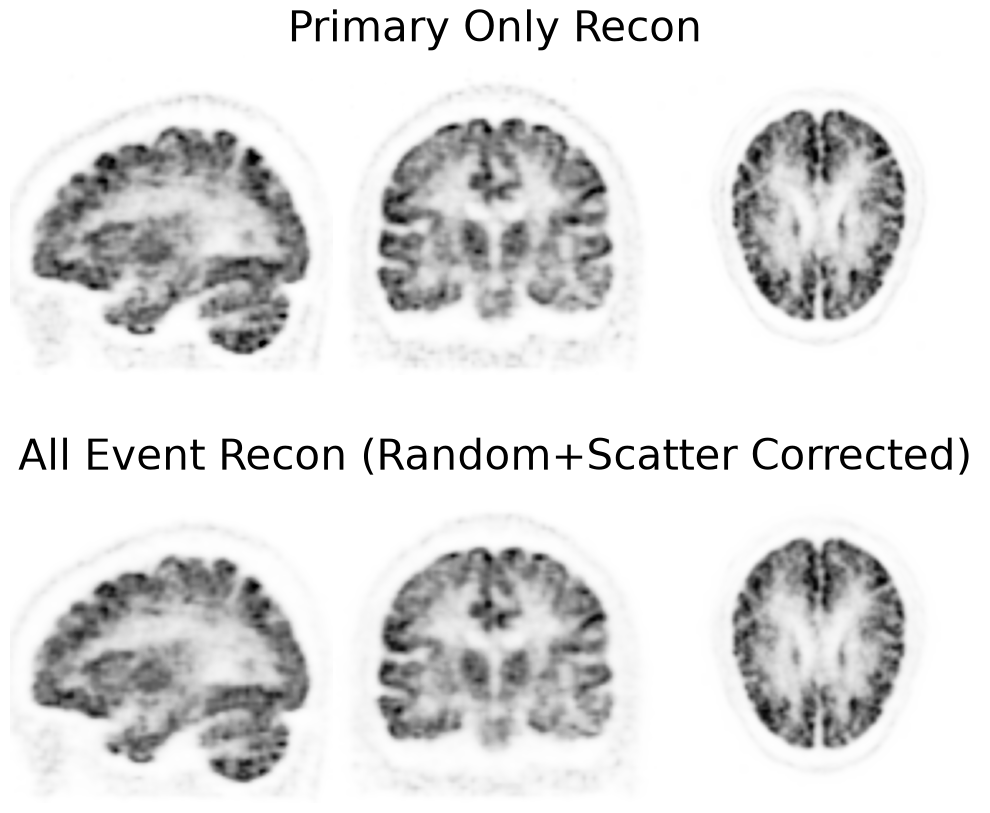

In [16]:
vmax = 0.45
cmap = 'Greys'
fig, ax = plt.subplots(2,3,figsize=(10,9), gridspec_kw={'wspace': 0.0})
plt.subplot(231)
plt.imshow(recon_primaryonly[48,16:-16].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.subplot(232)
plt.imshow(recon_primaryonly[16:-16,64].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.title('Primary Only Recon', fontsize=30)
plt.axis('off')
plt.subplot(233)
plt.imshow(recon_primaryonly[:,:,48].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.subplot(234)
plt.imshow(recon_lm_tof[48,16:-16].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.subplot(235)
plt.imshow(recon_lm_tof[16:-16,64].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
plt.title('All Event Recon (Random+Scatter Corrected)', fontsize=30)
plt.subplot(236)
plt.imshow(recon_lm_tof[:,:,48].cpu().T, cmap=cmap, vmax=vmax, interpolation='gaussian', origin='lower')
plt.axis('off')
fig.tight_layout()
plt.show()

## Save the images

`io.save_dicom` writes the reconstruction as a DICOM PET series, one file per slice, where `object_meta` places it. GATE data have no patient frame of their own: `read_gate` placed the grid on the phantom's MR, from the dataset registry's record of where the phantom sat in GATE's world, so it lines up with that NIfTI file in software that reads both, such as 3D Slicer.

In [17]:
saved = io.save_dicom(recon_lm_tof, OUTPUT / 't_PETGATE_scat_lmTOF' / 'osem', object_meta,
                      series_description='TOF list-mode OSEM, scatter and randoms corrected', overwrite=True)

In [18]:

import json, platform, torch, pytomography
def _peak_ram_gb():
    try:
        import psutil
        m = psutil.Process().memory_info()
        if hasattr(m, "peak_pagefile"):  # Windows: peak committed memory
            return round(m.peak_pagefile / 1e9, 1)
    except ImportError:
        pass
    import resource  # ru_maxrss is in kB on Linux, bytes on macOS
    return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e9 if platform.system() == "Darwin" else 1e6), 1)
_info = dict(pytomography=getattr(pytomography, "__version__", "?"), source=pytomography.__file__,
             torch=torch.__version__, python=platform.python_version(),
             gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
             peak_gpu_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else 0.0,
             peak_ram_gb=_peak_ram_gb())
print("__PYTOMOGRAPHY_RUN__" + json.dumps(_info))


__PYTOMOGRAPHY_RUN__{"pytomography": "4.0.0rc1", "source": "C:\\Users\\lukep\\miniforge3\\envs\\pytomo-rc1\\Lib\\site-packages\\pytomography\\__init__.py", "torch": "2.14.1+cu130", "python": "3.12.16", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "peak_gpu_gb": 3.44, "peak_ram_gb": 19.7}
